# 02 — Protocole de validation par faux trous simulés

Tous les scores du projet sortiront de ce protocole : il doit être **fidèle** (les faux trous ressemblent aux vrais), **étanche** (une méthode ne voit jamais la courbe qu'elle remplit) et **honnête** (le score final est mesuré sur des courbes qui n'ont servi à rien régler).

**Principe : la greffe de masques.** On prend le motif exact de NaN d'une vraie courbe trouée (train ou test) et on l'applique, aux mêmes horodates, à une courbe complète du train dont on connaît toutes les valeurs. Longueurs, calendrier des trous (blocs de 4 h, journées à minuit, trous de 2 points sur l'heure pile) et taux de trous par courbe sont ainsi reproduits à l'identique.

| Section | Contenu |
|---|---|
| a | L'hypothèse : les trous sont-ils indépendants des valeurs ? |
| b | Construction des trois jeux et règle anti-fuite |
| c | Fidélité du simulateur |
| d | Premier passage au registre : interpolation et KNN naïf |
| — | Constat → conséquence |

In [1]:
# Imports et configuration
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import PercentFormatter
from scipy.stats import spearmanr

from enedis_imputation import SEED
from enedis_imputation.data import load_test, load_train
from enedis_imputation.holes import LENGTH_LABELS, hole_runs, length_bucket
from enedis_imputation.methods import knn_median, linear_interpolation, scaled_median_fill
from enedis_imputation.validation import (
    EXCLUDED_MOTIFS,
    Split,
    bootstrap_mae,
    check_no_leak,
    evaluate,
    graft,
    load_registry,
    load_split,
    make_splits,
)
from enedis_imputation.viz import PALETTE as P
from enedis_imputation.viz import method_color, save_fig, set_conclusion, set_style

set_style()
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SPLIT_COLORS = {"dev": P["data"], "holdout": P["data_light"], "real": P["true"]}
SPLIT_LABELS = {
    "dev": "Dev (faux trous)",
    "holdout": "Holdout (faux trous)",
    "real": "Real (vrais trous)",
}

X_full, X_holed, y = load_train()
_, T_holed = load_test()
idx = X_holed.index

## a. L'hypothèse : les trous sont-ils indépendants des valeurs ?

La greffe n'est légitime que si **l'endroit où tombe un trou ne dépend pas de la consommation**. Si, par exemple, les compteurs décrochaient surtout lors des pics, les vrais trous cacheraient des valeurs plus élevées que des trous greffés au hasard, et le simulateur serait trop optimiste.

On le vérifie sur les 1 000 courbes trouées du train, dont `y_train` donne la vérité complète (et, quand c'est possible, sur le test, avec les seuls points observés).

In [2]:
# 1. Le taux de trous d'une courbe dépend-il de son profil ?
# Train : statistiques sur la vraie courbe complète (y). Test : sur les points observés.
keep = X_holed.columns.drop("holed_192")  # vérité entièrement NaN : inutilisable ici
Y = y[keep].to_numpy(np.float64)
M = X_holed[keep].isna().to_numpy()
T_obs = T_holed.mask(T_holed.isna()).to_numpy(np.float64)


def describe(values: np.ndarray) -> dict[str, np.ndarray]:
    """Niveau moyen, écart-type et part de zéros de chaque courbe (NaN ignorés)."""
    return {
        "niveau moyen": np.nanmean(values, axis=0),
        "écart-type": np.nanstd(values, axis=0),
        "part de zéros": np.nanmean(values == 0, axis=0),
    }


rows = {}
for jeu, values, rate in [
    ("train (vraie courbe)", Y, M.mean(axis=0)),
    ("test (points observés)", T_obs, T_holed.isna().to_numpy().mean(axis=0)),
]:
    for stat, v in describe(values).items():
        rho, p = spearmanr(rate, v)
        rows[(jeu, stat)] = {"ρ de Spearman": rho, "p-valeur": p}
corr = pd.DataFrame(rows).T
display(corr)
max_rho = corr["ρ de Spearman"].abs().max()
print(f"Plus forte corrélation (en valeur absolue) : {max_rho:.3f}")

ρ de Spearman  p-valeur
train (vraie courbe)   niveau moyen          -0.026     0.415
                       écart-type            -0.036     0.257
                       part de zéros          0.024     0.456
test (points observés) niveau moyen           0.042     0.186
                       écart-type             0.051     0.105
                       part de zéros         -0.035     0.268

Plus forte corrélation (en valeur absolue) : 0.051


In [3]:
# 2. Les valeurs dans les trous et à leurs bords sont-elles « normales » pour la courbe ?
# On compare chaque valeur au comportement habituel de SA courbe au MÊME créneau horaire
# (moyenne de la courbe sur les 22 jours à ce créneau), en unités d'écart-type de la courbe :
#     z = (valeur − moyenne du créneau) / écart-type de la courbe.
# Le créneau est indispensable : un trou d'une journée commence à minuit, la valeur juste
# avant est donc une valeur de 23 h 30, naturellement différente de la moyenne de la courbe.
slot = (idx.hour * 2 + idx.minute // 30).to_numpy()
profile = np.stack([Y[slot == s].mean(axis=0) for s in range(48)])  # (48 créneaux × courbes)
sd = Y.std(axis=0)
Z = (Y - profile[slot]) / np.where(sd > 0, sd, np.nan)  # courbes constantes : z indéfini

runs = hole_runs(M)
runs["classe"] = length_bucket(runs["length"])
n_curves = Y.shape[1]


def z_sums(rows_t: np.ndarray, cols: np.ndarray, lengths: np.ndarray) -> tuple:
    """Sommes et effectifs de z par courbe et par classe (pour le bootstrap par courbe)."""
    classes = length_bucket(lengths)
    z = Z[rows_t, cols]
    ok = ~np.isnan(z)
    sums = np.zeros((n_curves, len(LENGTH_LABELS)))
    counts = np.zeros((n_curves, len(LENGTH_LABELS)), dtype=np.int64)
    np.add.at(sums, (cols[ok], classes.codes[ok]), z[ok])
    np.add.at(counts, (cols[ok], classes.codes[ok]), 1)
    return sums, counts


positions = {}
# Dans les trous : chaque point manquant, avec la classe de son trou
pt_t, pt_c = np.nonzero(M)
pt_len = np.repeat(runs["length"].to_numpy(), runs["length"].to_numpy())
order = np.lexsort((pt_t, pt_c))  # même ordre que hole_runs : courbe, puis temps
positions["dans le trou"] = z_sums(pt_t[order], pt_c[order], pt_len)
# Juste avant et juste après chaque trou
for name, t in [
    ("juste avant", runs["start"] - 1),
    ("juste après", runs["start"] + runs["length"]),
]:
    ok = ((t >= 0) & (t < len(idx))).to_numpy()
    positions[name] = z_sums(
        t.to_numpy()[ok], runs["curve"].to_numpy()[ok], runs["length"].to_numpy()[ok]
    )

z_table = {}
for name, (sums, counts) in positions.items():
    boot = bootstrap_mae(sums, counts)  # estimateur de ratio générique : Σz / n, par courbe
    with np.errstate(invalid="ignore"):
        point = np.append(sums.sum(0) / counts.sum(0), sums.sum() / counts.sum())
    low, high = np.nanpercentile(boot, [2.5, 97.5], axis=0)
    for i, c in enumerate([*LENGTH_LABELS, "toutes"]):
        z_table[(name, c)] = {"z moyen": point[i], "IC bas": low[i], "IC haut": high[i]}
z_table = pd.DataFrame(z_table).T
display(z_table.xs("toutes", level=1))
max_abs_z = z_table.loc[(slice(None), "toutes"), "z moyen"].abs().max()

,z moyen,IC bas,IC haut
dans le trou,0.005,-0.006,0.016
juste avant,0.002,-0.005,0.009
juste après,0.003,-0.004,0.009


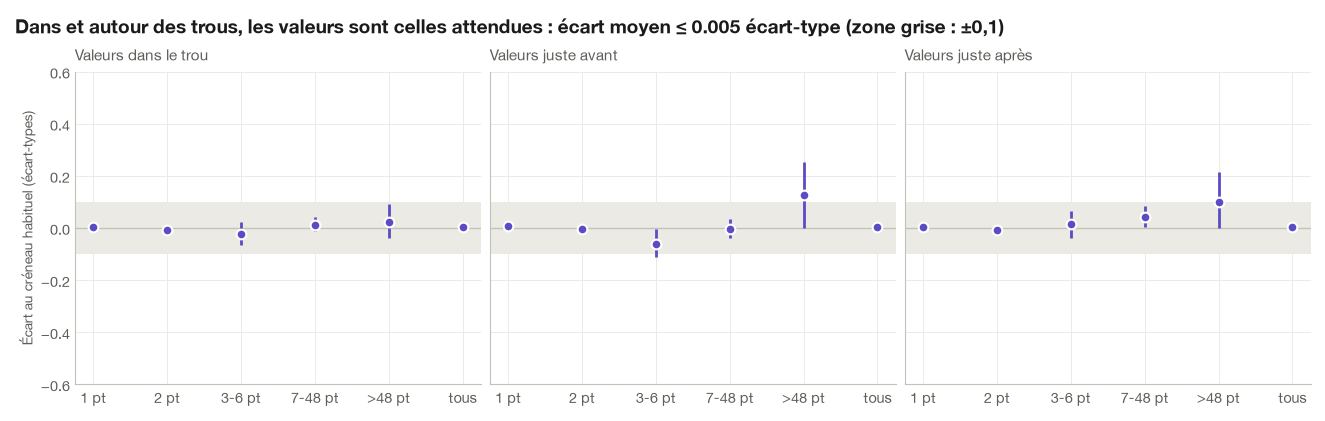

In [4]:
# Figure : z moyen par position et par classe de trou, avec IC à 95 %
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, name in zip(axes, positions, strict=True):
    t = z_table.xs(name, level=0)
    x = np.arange(len(t))
    ax.axhspan(-0.1, 0.1, color=P["grid"], lw=0, zorder=0)
    ax.axhline(0, color=P["axis"], lw=1)
    ax.errorbar(
        x,
        t["z moyen"],
        yerr=[t["z moyen"] - t["IC bas"], t["IC haut"] - t["z moyen"]],
        fmt="o",
        color=P["data"],
        ms=7,
        mec="white",
        mew=1.5,
        elinewidth=2,
        capsize=0,
    )
    ax.set_xticks(x, [f"{c} pt" if c != "toutes" else "tous" for c in t.index])
    ax.set_title(f"Valeurs {name}")
axes[0].set_ylabel("Écart au créneau habituel (écart-types)")
axes[0].set_ylim(-0.6, 0.6)
set_conclusion(
    fig,
    f"Dans et autour des trous, les valeurs sont celles attendues : écart moyen ≤ {max_abs_z:.3f} "
    "écart-type (zone grise : ±0,1)",
)
save_fig(fig, "v1_trous_independants");

In [5]:
# 3. holed_192 et le traitement de secours
w = X_holed["holed_192"]
print(
    f"holed_192 : {w.notna().sum()} point observé sur {len(w)}, "
    f"vérité disponible sur {y['holed_192'].notna().sum()} point(s)"
)
print(f"Taux de NaN maximal des courbes trouées du test : {T_holed.isna().mean().max():.1%}")
print("Motifs exclus de la greffe :", EXCLUDED_MOTIFS)

holed_192 : 1 point observé sur 1057, vérité disponible sur 1 point(s)
Taux de NaN maximal des courbes trouées du test : 33.1%
Motifs exclus de la greffe : ('train:holed_192',)


In [6]:
# Faut-il un traitement de secours pour une courbe presque vide ? On simule des courbes
# dont il ne reste que n points observés d'affilée (n = 1, 12, 48, 144), en partant de 300
# cibles du jeu dev (absentes du réservoir), et on compare les méthodes.
dev = load_split("dev")
cols = rng.choice(dev.y.columns, 300, replace=False)
T = len(idx)


def reservoir_median(X: pd.DataFrame, R: pd.DataFrame) -> pd.DataFrame:
    """Médiane du réservoir à chaque instant, sans tenir compte des points observés."""
    prof = np.median(R.to_numpy(np.float32), axis=1)
    return X.fillna(pd.DataFrame(np.repeat(prof[:, None], X.shape[1], 1), X.index, X.columns))


candidates = {
    "Interpolation linéaire": linear_interpolation,
    "KNN naïf (médiane de 5)": knn_median,
    "Médiane du réservoir mise à l'échelle": scaled_median_fill,
    "Médiane du réservoir (brute)": reservoir_median,
}
sweep = {}
for n in [1, 12, 48, 144]:
    keep_mask = np.ones((T, len(cols)), dtype=bool)
    for j, s in enumerate(rng.integers(0, T - n, size=len(cols))):
        keep_mask[s : s + n, j] = False  # seuls n points d'affilée restent observés
    sp = Split("dev", graft(dev.y[cols], keep_mask), dev.y[cols], dev.reservoir)
    check_no_leak(sp.X_holed, sp.reservoir)
    sweep[f"{n} pt observé(s)"] = {
        k: evaluate(m, sp, name=k, register=False).mae for k, m in candidates.items()
    }
sweep = pd.DataFrame(sweep)
display(sweep.round(1).rename_axis("MAE (W)"))
print("Meilleure méthode selon le nombre de points observés :", sweep.idxmin().to_dict())

,1 pt observé(s),12 pt observé(s),48 pt observé(s),144 pt observé(s)
MAE (W),,,,
Interpolation linéaire,170.500,173.500,174.800,175.800
KNN naïf (médiane de 5),172.500,146.600,132.000,126.500
Médiane du réservoir mise à l'échelle,168.300,157.700,140.900,137.100
Médiane du réservoir (brute),265.000,265.000,264.600,264.800


Meilleure méthode selon le nombre de points observés : {'1 pt observé(s)': "Médiane du réservoir mise à l'échelle", '12 pt observé(s)': 'KNN naïf (médiane de 5)', '48 pt observé(s)': 'KNN naïf (médiane de 5)', '144 pt observé(s)': 'KNN naïf (médiane de 5)'}


### Constat → conséquence pour la modélisation

**Constat**
- **Aucun lien entre le taux de trous d'une courbe et son profil.** Les corrélations de Spearman avec le niveau moyen, l'écart-type et la part de zéros sont toutes inférieures à 0,06 en valeur absolue, et aucune n'est significative (p ≥ 0,10). C'est vrai sur le train (vraie courbe complète) comme sur le test (points observés).
- **Les valeurs cachées par les trous sont normales pour leur courbe.** Comparées au comportement habituel de la courbe au même créneau horaire, elles s'en écartent en moyenne de **+0,005 écart-type**, avec un IC à 95 % de [−0,006 ; +0,016]. Les valeurs juste avant et juste après un trou s'écartent de +0,002 et +0,003 écart-type. Par classe de longueur, tous les écarts restent dans ±0,1 écart-type.
- Seule exception : juste avant et juste après les ~190 trous de plus de 48 points, l'écart atteint +0,13 et +0,10. C'est peu, l'intervalle frôle 0, et les valeurs *dans* ces trous restent normales (+0,02).
- **`holed_192` est exclue des motifs.** Elle ne garde qu'un point observé, sa vérité est entièrement NaN (elle ne compte donc pas dans la MAE du jeu real), et aucune courbe du test ne lui ressemble : la plus trouée l'est à 33 %. La greffer créerait une cible de 1 056 points à prédire pour un cas qui n'existe pas dans le test.
- **Secours pour courbe presque vide.** On a gardé seulement n points d'affilée sur 300 cibles :
  - avec 1 seul point, toutes les méthodes se valent (~170 W) ;
  - dès 12 points (6 h), le **KNN est nettement le meilleur**, devant la médiane du réservoir mise à l'échelle ;
  - la médiane brute du réservoir, qui ignore le niveau de la courbe, est de loin la pire (~265 W).

**→ Conséquence**
- **La greffe de masques est légitime.** La position des trous ne dépend pas des valeurs : elle n'est déterminée que par le calendrier (points isolés, blocs d'1 h, blocs de 4 h, journées à minuit), que la greffe reproduit exactement. Un faux trou est donc un tirage de même loi qu'un vrai.
- **Le secours ne sert que pour une courbe sans aucun point observé**, où ni l'interpolation ni le KNN ne peuvent rien faire. C'est le réglage par défaut de `with_fallback` : profil médian du réservoir. Pour toutes les autres, le KNN se dégrade bien et suffit. Le test n'en contient d'ailleurs aucune.

## b. Construction des trois jeux et règle anti-fuite

In [7]:
meta = make_splits()  # construit une fois, puis relu depuis data/processed/
splits = {name: load_split(name) for name in ("dev", "holdout", "real")}
reservoir_cols = set(splits["dev"].reservoir.columns)

summary = pd.DataFrame(
    {
        name: {
            "courbes à remplir": s.X_holed.shape[1],
            "réservoir de voisins": s.reservoir.shape[1],
            "taux de NaN": s.mask.mean(),
            "motifs issus du train": sum(m.startswith("train:") for m in s.motifs or [])
            if s.motifs
            else np.nan,
            "motifs issus du test": sum(m.startswith("test:") for m in s.motifs or [])
            if s.motifs
            else np.nan,
        }
        for name, s in splits.items()
    }
)
display(summary)

# Règle anti-fuite : aucune courbe cible dans le réservoir, jeux de cibles disjoints
for s in splits.values():
    check_no_leak(s.X_holed, s.reservoir)
overlap = set(splits["dev"].X_holed.columns) & set(splits["holdout"].X_holed.columns)
print(
    "Cibles dans le réservoir :",
    sum(len(set(s.X_holed.columns) & reservoir_cols) for s in splits.values()),
)
print("Cibles communes dev / holdout :", len(overlap))

,dev,holdout,real
courbes à remplir,"1,999.000","1,999.000","1,000.000"
réservoir de voisins,"16,001.000","16,001.000","16,001.000"
taux de NaN,0.122,0.122,0.123
motifs issus du train,999.000,999.000,NaN
motifs issus du test,"1,000.000","1,000.000",NaN


Cibles dans le réservoir : 0
Cibles communes dev / holdout : 0


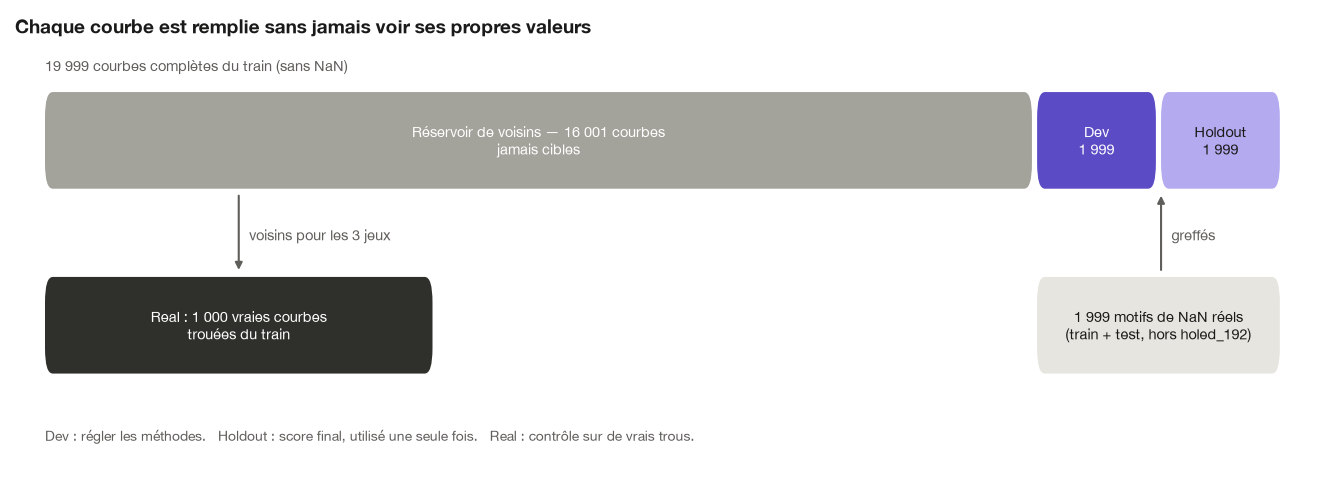

In [8]:
# Schéma du protocole
n_res, n_dev, n_hold = (
    len(reservoir_cols),
    splits["dev"].X_holed.shape[1],
    splits["holdout"].X_holed.shape[1],
)
n_total = n_res + n_dev + n_hold

fig, ax = plt.subplots(figsize=(13, 4.6))
ax.set_xlim(0, 100)
ax.set_ylim(0, 10)
ax.set_axis_off()


def fr(n: int) -> str:
    """Formate un entier avec une espace comme séparateur de milliers (16 001)."""
    return f"{n:,}".replace(",", " ")


def block(
    x: float, yb: float, w: float, h: float, color: str, text: str, ink: str = "white"
) -> None:
    """Dessine un bloc arrondi avec son libellé centré."""
    ax.add_patch(
        FancyBboxPatch((x, yb), w, h, boxstyle="round,pad=0,rounding_size=0.6", fc=color, ec="none")
    )
    ax.text(x + w / 2, yb + h / 2, text, ha="center", va="center", color=ink, fontsize=10.5)


# Ligne 1 : courbes complètes du train, découpées
x0, width = 2, 96
w_res, w_dev = width * n_res / n_total, width * n_dev / n_total
ax.text(
    x0,
    9.4,
    f"{fr(n_total)} courbes complètes du train (sans NaN)",
    color=P["ink_secondary"],
    fontsize=10.5,
)
block(
    x0,
    6.6,
    w_res - 0.4,
    2.3,
    P["neutral"],
    f"Réservoir de voisins — {fr(n_res)} courbes\njamais cibles",
)
block(x0 + w_res, 6.6, w_dev - 0.4, 2.3, P["data"], f"Dev\n{fr(n_dev)}")
block(
    x0 + w_res + w_dev,
    6.6,
    w_dev - 0.4,
    2.3,
    P["data_light"],
    f"Holdout\n{fr(n_hold)}",
    ink=P["ink"],
)

# Ligne 2 : motifs et vraies courbes trouées
block(
    x0 + w_res,
    2.2,
    2 * w_dev - 0.4,
    2.3,
    P["hole"],
    f"{fr(n_dev)} motifs de NaN réels\n(train + test, hors holed_192)",
    ink=P["ink"],
)
block(x0, 2.2, 30, 2.3, P["true"], "Real : 1 000 vraies courbes\ntrouées du train")
ax.annotate(
    "",
    xy=(x0 + w_res + w_dev, 6.5),
    xytext=(x0 + w_res + w_dev, 4.6),
    arrowprops={"arrowstyle": "-|>", "color": P["ink_secondary"], "lw": 1.5},
)
ax.text(x0 + w_res + w_dev + 0.8, 5.5, "greffés", color=P["ink_secondary"], va="center")
ax.annotate(
    "",
    xy=(x0 + 15, 6.5),
    xytext=(x0 + 15, 4.6),
    arrowprops={"arrowstyle": "<|-", "color": P["ink_secondary"], "lw": 1.5},
)
ax.text(x0 + 15.8, 5.5, "voisins pour les 3 jeux", color=P["ink_secondary"], va="center")
ax.text(
    x0,
    0.6,
    "Dev : régler les méthodes.   Holdout : score final, utilisé une seule fois.   "
    "Real : contrôle sur de vrais trous.",
    color=P["ink_secondary"],
    fontsize=10,
)
set_conclusion(fig, "Chaque courbe est remplie sans jamais voir ses propres valeurs")
save_fig(fig, "v2_protocole");

## c. Fidélité du simulateur

,dev,holdout,real
nb de trous par courbe,55.952,55.952,55.966
part trous 1 pt,0.751,0.751,0.751
part trous > 48 pts,0.004,0.004,0.003
part valeurs 1,0.326,0.326,0.324
part valeurs 2,0.162,0.162,0.161
part valeurs 3-6,0.030,0.030,0.030
part valeurs 7-48,0.387,0.387,0.388
part valeurs >48,0.094,0.094,0.097
trous de 8 pts sur 0/4/8/…/20 h,1.000,1.000,1.000
trous de 48 pts à minuit,1.000,1.000,1.000


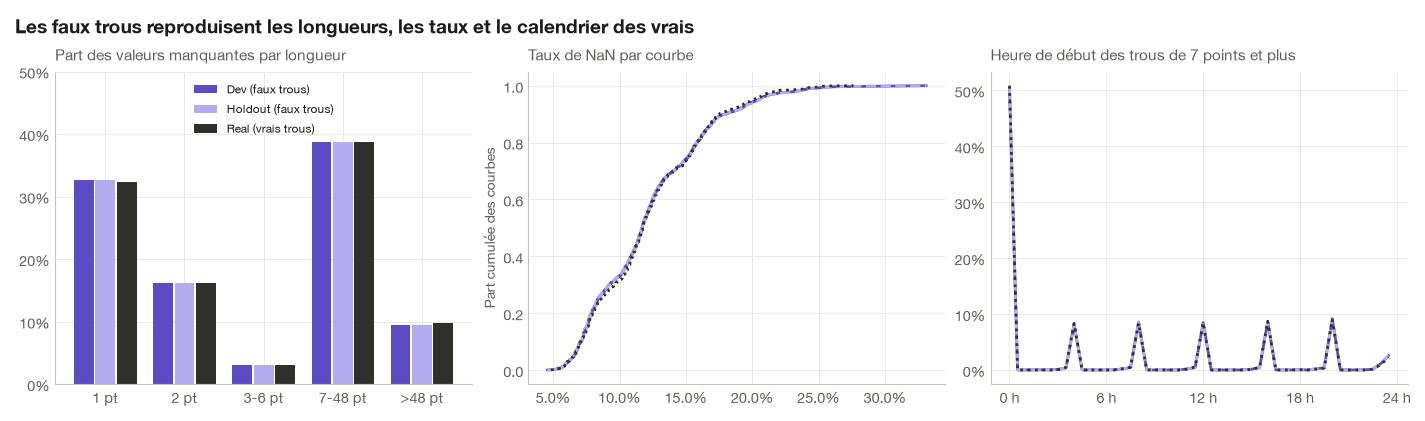

In [9]:
# Longueurs et calendrier : faux trous (dev, holdout) contre vrais trous (real)
hole_stats = {}
for name, s in splits.items():
    r = hole_runs(s.mask)
    r["classe"] = length_bucket(r["length"])
    start = s.X_holed.index[r["start"].to_numpy()]
    r["créneau"] = start.hour * 2 + start.minute // 30
    hole_stats[name] = r

fid = pd.DataFrame(
    {
        name: {
            "nb de trous par courbe": len(r) / splits[name].X_holed.shape[1],
            "part trous 1 pt": (r["length"] == 1).mean(),
            "part trous > 48 pts": (r["length"] > 48).mean(),
            **(r.groupby("classe", observed=False)["length"].sum() / r["length"].sum())
            .add_prefix("part valeurs ")
            .to_dict(),
            "trous de 8 pts sur 0/4/8/…/20 h": (r.loc[r["length"] == 8, "créneau"] % 8 == 0).mean(),
            "trous de 48 pts à minuit": (r.loc[r["length"] == 48, "créneau"] == 0).mean(),
        }
        for name, r in hole_stats.items()
    }
)
display(fid)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
x = np.arange(len(LENGTH_LABELS))
for i, (name, r) in enumerate(hole_stats.items()):
    share = r.groupby("classe", observed=False)["length"].sum() / r["length"].sum()
    ax.bar(
        x + (i - 1) * 0.27,
        share.to_numpy(),
        width=0.25,
        color=SPLIT_COLORS[name],
        label=SPLIT_LABELS[name],
    )
ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Part des valeurs manquantes par longueur")
ax.set_ylim(0, 0.5)
ax.legend(fontsize=8.5, loc="upper center", ncol=1)
ax = axes[1]
for name, s in splits.items():
    v = np.sort(s.mask.mean(axis=0))
    v = v[v < 0.9]
    ax.plot(
        v,
        np.arange(1, len(v) + 1) / len(v),
        color=SPLIT_COLORS[name],
        lw=2,
        ls={"dev": "-", "holdout": "--", "real": ":"}[name],
        label=SPLIT_LABELS[name],
    )
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Part cumulée des courbes")
ax.set_title("Taux de NaN par courbe")
ax = axes[2]
for name, r in hole_stats.items():
    long = r[r["length"] >= 7]
    share = long["créneau"].value_counts(normalize=True).reindex(range(48), fill_value=0)
    ax.plot(
        np.arange(48) / 2,
        share.to_numpy(),
        color=SPLIT_COLORS[name],
        lw=2,
        ls={"dev": "-", "holdout": "--", "real": ":"}[name],
        label=SPLIT_LABELS[name],
    )
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xticks(range(0, 25, 6), [f"{h} h" for h in range(0, 25, 6)])
ax.set_title("Heure de début des trous de 7 points et plus")
set_conclusion(
    fig, "Les faux trous reproduisent les longueurs, les taux et le calendrier des vrais"
)
save_fig(fig, "v3_fidelite_trous");

In [10]:
# Figure clé : MAE de l'interpolation linéaire par classe, sur les trois jeux.
# Le benchmark n'a aucun paramètre : l'évaluer sur le holdout ne règle rien. C'est la seule
# exception à la règle « holdout à la fin », et elle sert de référence au score final.
interp = {
    name: evaluate(linear_interpolation, s, name="Interpolation linéaire", allow_holdout=True)
    for name, s in splits.items()
}


def with_global(r) -> pd.DataFrame:
    """Tableau par classe complété d'une ligne « toutes »."""
    g = pd.DataFrame(
        {
            "mae": [r.mae],
            "low": [r.ci[0]],
            "high": [r.ci[1]],
            "points": [r.by_class["points"].sum()],
        },
        index=["toutes"],
    )
    return pd.concat([r.by_class, g])


tables = {name: with_global(r) for name, r in interp.items()}
mae_table = pd.DataFrame({name: t["mae"] for name, t in tables.items()})
display(mae_table.rename_axis("MAE interpolation (W)").round(1))

gap = (mae_table[["dev", "holdout"]].sub(mae_table["real"], axis=0)).div(mae_table["real"], axis=0)
overlap = all(
    max(tables[a].loc[c, "low"], tables["real"].loc[c, "low"])
    <= min(tables[a].loc[c, "high"], tables["real"].loc[c, "high"])
    for a in ("dev", "holdout")
    for c in mae_table.index
)
print("Écart relatif à real :")
display(gap.style.format("{:+.1%}"))
print("Tous les intervalles de confiance chevauchent celui de real :", overlap)

,dev,holdout,real
MAE interpolation (W),,,
1,62.200,58.600,62.100
2,71.900,67.500,71.200
3-6,77.400,76.800,78.700
7-48,143.400,140.100,139.800
>48,154.100,150.800,145.400
toutes,104.300,100.800,102.000


Écart relatif à real :


,dev,holdout
1,+0.2%,-5.7%
2,+1.0%,-5.2%
3-6,-1.6%,-2.4%
7-48,+2.5%,+0.2%
>48,+6.0%,+3.7%
toutes,+2.3%,-1.1%


Tous les intervalles de confiance chevauchent celui de real : True


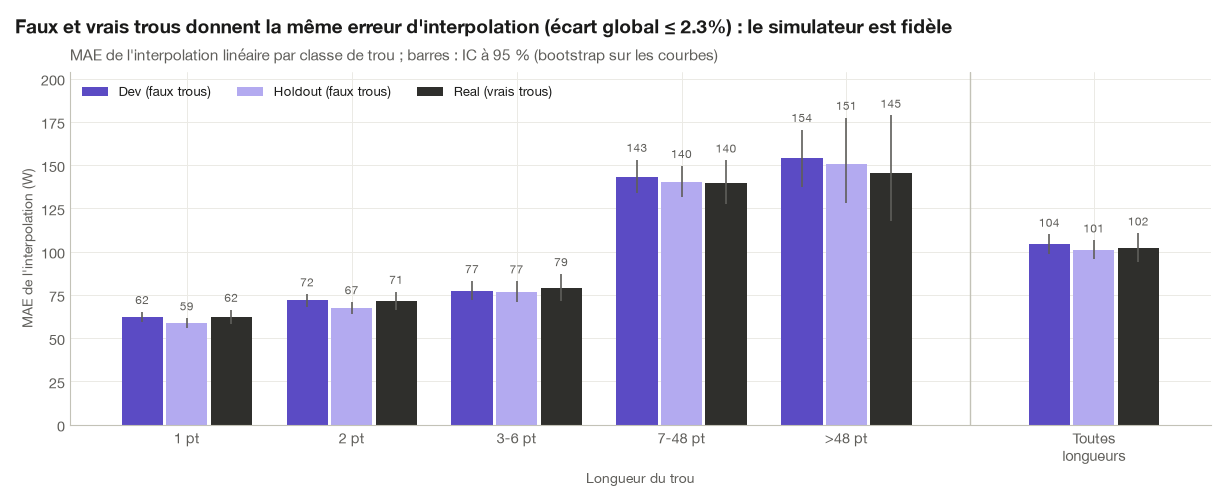

In [11]:
fig, ax = plt.subplots(figsize=(12, 4.8))
groups = [*LENGTH_LABELS, "toutes"]
x = np.arange(len(groups)) + np.array([0, 0, 0, 0, 0, 0.5])  # « toutes » un peu à l'écart
for i, name in enumerate(["dev", "holdout", "real"]):
    t = tables[name].loc[groups]
    xs = x + (i - 1) * 0.27
    ax.bar(xs, t["mae"], width=0.25, color=SPLIT_COLORS[name], label=SPLIT_LABELS[name])
    ax.errorbar(
        xs,
        t["mae"],
        yerr=[t["mae"] - t["low"], t["high"] - t["mae"]],
        fmt="none",
        ecolor=P["ink_secondary"],
        elinewidth=1.2,
        capsize=0,
    )
    for xi, v, hi in zip(xs, t["mae"], t["high"], strict=True):
        ax.text(
            xi, hi + 3, f"{v:.0f}", ha="center", va="bottom", fontsize=8.5, color=P["ink_secondary"]
        )
ax.axvline(x[-1] - 0.75, color=P["axis"], lw=1)
ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS] + ["Toutes\nlongueurs"])
ax.set_xlabel("Longueur du trou")
ax.set_ylabel("MAE de l'interpolation (W)")
ax.set_ylim(0, tables["holdout"]["high"].max() * 1.15)
ax.set_title(
    "MAE de l'interpolation linéaire par classe de trou ; barres : IC à 95 % "
    "(bootstrap sur les courbes)"
)
ax.legend(loc="upper left", ncol=3)
worst = gap.loc["toutes"].abs().max()
set_conclusion(
    fig,
    f"Faux et vrais trous donnent la même erreur d'interpolation (écart global ≤ {worst:.1%}) : "
    "le simulateur est fidèle",
)
save_fig(fig, "v4_simulateur_fidele");

## d. Premier passage au registre : le KNN naïf

Chaque courbe est remplie par la médiane de ses 5 plus proches voisines du réservoir (distance MAE sur ses points observés). On l'évalue sur **dev**, et sur **real** comme second contrôle de fidélité : si le simulateur est bon, le KNN doit, lui aussi, obtenir la même erreur sur faux et vrais trous.

KNN dev : MAE 106.12 W, IC95 [101.2, 111.1], 27 s
KNN real : MAE 103.45 W, IC95 [97.0, 110.8], 13 s


,Interpolation (dev),KNN naïf (dev),KNN naïf (real)
1,62.200,104.600,103.200
2,71.900,103.700,101.700
3-6,77.400,107.000,107.900
7-48,143.400,106.600,105.400
>48,154.100,113.500,97.600
toutes,104.300,106.100,103.400


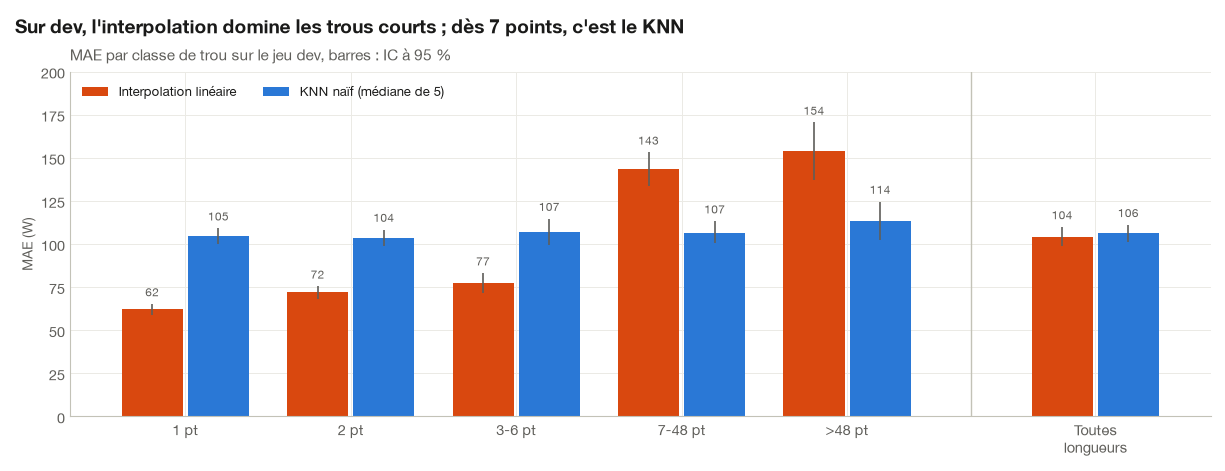

In [12]:
knn = {
    name: evaluate(knn_median, splits[name], name="KNN naïf (médiane de 5)")
    for name in ("dev", "real")
}
for name, r in knn.items():
    print(f"KNN {name} : MAE {r.mae:.2f} W, IC95 [{r.ci[0]:.1f}, {r.ci[1]:.1f}], {r.seconds:.0f} s")

comp = pd.DataFrame(
    {
        "Interpolation (dev)": tables["dev"]["mae"],
        "KNN naïf (dev)": with_global(knn["dev"])["mae"],
        "KNN naïf (real)": with_global(knn["real"])["mae"],
    }
)
display(comp.round(1))

fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(groups)) + np.array([0, 0, 0, 0, 0, 0.5])
for off, label, t in [
    (-0.2, "Interpolation linéaire", tables["dev"]),
    (0.2, "KNN naïf (médiane de 5)", with_global(knn["dev"])),
]:
    t = t.loc[groups]
    ax.bar(x + off, t["mae"], width=0.37, color=method_color(label), label=label)
    ax.errorbar(
        x + off,
        t["mae"],
        yerr=[t["mae"] - t["low"], t["high"] - t["mae"]],
        fmt="none",
        ecolor=P["ink_secondary"],
        elinewidth=1.2,
    )
    for xi, v, hi in zip(x + off, t["mae"], t["high"], strict=True):
        ax.text(
            xi, hi + 3, f"{v:.0f}", ha="center", va="bottom", fontsize=8.5, color=P["ink_secondary"]
        )
ax.axvline(x[-1] - 0.75, color=P["axis"], lw=1)
ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS] + ["Toutes\nlongueurs"])
ax.set_ylabel("MAE (W)")
ax.set_ylim(0, 200)
ax.set_title("MAE par classe de trou sur le jeu dev, barres : IC à 95 %")
ax.legend(loc="upper left", ncol=2)
knn_wins = knn["dev"].by_class["mae"] < interp["dev"].by_class["mae"]
first_win = knn_wins.idxmax()  # première classe gagnée par le KNN, ex. "7-48"
threshold = int(first_win.split("-")[0].lstrip(">")) + first_win.startswith(">")
set_conclusion(
    fig,
    f"Sur dev, l'interpolation domine les trous courts ; dès {threshold} points, c'est le KNN",
)
save_fig(fig, "v5_interp_vs_knn_dev");

In [13]:
# Aperçu de l'étape suivante : si l'on choisissait, pour chaque classe de trou, la meilleure
# des deux méthodes (choix fait sur dev), quelle MAE obtiendrait-on ?
per_class = pd.DataFrame(
    {"interp": interp["dev"].by_class["mae"], "knn": knn["dev"].by_class["mae"]}
).assign(points=interp["dev"].by_class["points"])
per_class["meilleure"] = per_class[["interp", "knn"]].min(axis=1)
combo = (per_class["meilleure"] * per_class["points"]).sum() / per_class["points"].sum()
print(
    f"Combinaison « meilleure méthode par classe » sur dev : {combo:.1f} W "
    f"(interpolation seule : {interp['dev'].mae:.1f} W, soit {combo / interp['dev'].mae - 1:+.0%})"
)

Combinaison « meilleure méthode par classe » sur dev : 86.2 W (interpolation seule : 104.3 W, soit -17%)


In [14]:
# Registre des résultats (reports/results.csv, versionné) : dernière évaluation par couple
registry = load_registry()
registry[
    [
        "method",
        "split",
        "mae",
        "mae_ci_low",
        "mae_ci_high",
        *[f"mae_{c}" for c in LENGTH_LABELS],
        "seconds",
    ]
]

,method,split,mae,mae_ci_low,mae_ci_high,mae_1,mae_2,mae_3-6,mae_7-48,mae_>48,seconds
0,Interpolation linéaire,dev,104.287,98.521,109.870,62.195,71.877,77.430,143.360,154.056,0.130
1,Interpolation linéaire,holdout,100.798,95.572,106.565,58.581,67.488,76.806,140.081,150.763,0.110
2,Interpolation linéaire,real,101.951,94.022,110.605,62.095,71.188,78.669,139.821,145.381,0.050
3,KNN naïf (médiane de 5),dev,106.119,101.233,111.106,104.594,103.658,106.985,106.566,113.546,26.630
4,KNN naïf (médiane de 5),real,103.449,96.996,110.777,103.207,101.675,107.941,105.372,97.638,13.070


## Constat → conséquence pour la modélisation

**Constat**
- **Trois jeux étanches** :
  - dev et holdout : 1 999 courbes cibles chacun ;
  - real : 1 000 vraies courbes trouées ;
  - un réservoir commun de 16 001 courbes.
  
  Aucune cible dans le réservoir, aucune cible commune à dev et holdout. Les 2 paires de courbes identiques du train (hors courbes nulles) sont interdites comme cibles, pour qu'un double ne puisse pas remplir sa copie. Tout cela est vérifié à chaque évaluation et par les tests pytest.
- **Structure des trous identique** entre faux et vrais trous : même nombre de trous par courbe (56), mêmes parts par classe (±0,3 point), 100 % des blocs de 8 points sur une frontière de 4 h, 100 % des journées à minuit.
- **Même erreur d'interpolation sur faux et vrais trous** :
  - MAE globale de 104,3 W (dev), 100,8 W (holdout) et 102,0 W (real), soit +2,3 % et −1,1 % par rapport à real ;
  - **tous les intervalles de confiance se chevauchent**, classe par classe.
  
  Les écarts entre dev et holdout (par exemple 62 contre 59 W sur les trous d'un point) mesurent la variabilité naturelle d'un échantillon de 2 000 courbes, de l'ordre de 5 % par classe.
- **Second contrôle avec le KNN naïf** : 106,1 W sur dev contre 103,4 W sur real, et 103 W mesurés au départ du projet. Le simulateur est fidèle pour deux méthodes de nature très différente.
- **Les deux méthodes sont complémentaires** :
  - l'interpolation gagne nettement jusqu'à 6 points ;
  - le KNN, dont l'erreur est presque plate (~105–115 W quelle que soit la longueur), gagne sur les trous de 7 points et plus, de 143 à 107 W et de 154 à 114 W.
  
  Choisir la meilleure méthode par classe donnerait déjà ~86 W sur dev.

**→ Conséquence**
- **Toutes les décisions** (choix de méthode, hyperparamètres, seuils de combinaison) **se prennent sur dev.** Le **holdout ne sert qu'une fois, à la fin**, pour le score final. Seul le benchmark sans paramètre y a été évalué, pour servir de référence. **Real** reste un contrôle sur de vrais trous.
- **Lire les gains à la lumière de l'incertitude** : l'IC global fait environ ±5 W. Comparer deux méthodes sur les *mêmes* courbes dev est beaucoup plus précis (comparaison appariée) ; un bootstrap apparié des différences sera ajouté quand les écarts deviendront serrés.
- **Prochaine étape : le KNN**, à améliorer là où il gagne, les trous longs, puis la **combinaison selon la longueur du trou**. La cible immédiate est de passer sous ~86 W sur dev.
- Chaque évaluation ajoute une ligne à `reports/results.csv`, qui alimentera le tableau et le graphique final du README.